# Inventario de movimientos en masa

## Objetivos de aprendizaje

Al finalizar este capítulo, el estudiante será capaz de:

- Comprender la importancia del inventario de movimientos en masa como insumo fundamental para la cartografía geotécnica.
- Cargar y visualizar datos raster de inventario de movimientos en masa con `rasterio` y `matplotlib`.
- Interpretar la distribución espacial de los movimientos en masa en relación con las variables del terreno.
- Describir los tipos de inventario (histórico, geomorfológico, multi-temporal) y sus aplicaciones en la estimación de susceptibilidad.

**Duración estimada:** 1–2 horas

## Requisitos previos

Para seguir este capítulo se recomienda conocimiento básico en:

- **Python:** estructuras básicas (listas, arrays NumPy), instalación de paquetes con `pip`.
- **SIG:** conceptos de datos raster (resolución, sistema de referencia, NoData), visualización de mapas.
- **Geología/Geomorfología:** clasificación de movimientos en masa (Varnes 1978), procesos de ladera.

**Capítulo anterior recomendado:** `00_introduccion`, `01_normatividad`.

La elaboración de un mapa de susceptibilidad y/o amenaza por movimientos en masa se refiere a la construcción de un modelo predictivo de la forma:

$y = f(X)$

Donde $y$ es la variable dependiente, es decir la ocurrencia o no de movimientos en masa; y $X$ correponde a las variables independientes o condicionantes. 

$MenM[0,1] = f(pendiente, geologia, coberturas, etc, etc,)$

De esta forma, el inventario de movimientos en masa es una herramienta fundamental para la evaluación de la probabilidad espacial, temporal y magnitud. Además, constituyen la principal fuente de información con fines de validación de los resultados de los mapas de zonificación de la amenaza. El inventario de movimientos en masa corresponde a un registro detallado de los eventos que han ocurrido en el pasado proporcionando información útil sobre su distribución y características ({cite:t}`eeckhaut2012`).

## Atributos de los movimientos en masa
Los atributos asociados a los movimientos en masa contienen información sobre:
* el tipo de deslizamiento
* la actividad
* el tamaño o volumen
* la fecha de ocurrencia o edad relativa
* las causas

## Técnicas
Existen múltiples técnicas para el levantamiento de inventarios:

* análisis de información histórica
* fotointerpretación de fotografías aéreas
* análisis visual de modelos digitales del terreno
* procesamiento de imágenes de satélite
* Levantamiento de 

Debido al acelerado desarrollo de las técnicas de sensores remotos, y la disponibilidad, cada vez mayor de esta información, se vienen desarrollando técnicas basadas en imágenes satelitales o modelos de elevación del terreno que faciliten la identificación y mapeo de los movimientos en masa. Entre ellas se resaltan el uso de índices espectrales, tales como el Índice de Diferencia Normalizada de Vegetación (NDVI). En donde se pueden identificar áreas cubiertas por vegetación y que por causa de movimientos en masa pierden dicha cobertura a suelos desnudos. Para esto se debe utilizar una imagen previa a la ocurrencia del evento, y otra imagen posterior y calcular el NDVI para cada una de ellas y posteriormente la diferencia entre dichos índices calculados. Las zonas de movimientos en masa representan las celdas con valores diferentes a cero, señalando el cambio de cobertura.

:::{figure-md} inventario-tipo
<img src="https://www.researchgate.net/profile/Dario-Gioia-2/publication/234111493/figure/fig2/AS:393517898715136@1470833386263/Landslide-inventory-map-of-the-study-area-Landslides-types-are-classified-according-to.png" alt="inventario" width="800px">

Inventario de movimientos en masa por tipo de evento. Tomado de Santagelo et al., (2013)
:::

:::{figure-md} inventario-actividad
<img src="https://d3i71xaburhd42.cloudfront.net/b29fda1ca9630cdb7118a107d420a8f7b91406ad/5-Figure3-1.png" alt="inventario" width="800px">

Inventario de movimientos en masa por actividad. Tomado de Ventisette et al (2014).
:::

## Tipos de inventarios
Existen los siguientes tipos de inventarios de movimientos en masa:

* **Inventario de movimientos en masa multitemporales**: son elaborados a partir de información de diferentes periodos de tiempo, por lo tanto permiten establecer la fecha o rango de ocurrencia de los eventos. Cuando se utilizan fotografías aéreas o imágenes satelitales, se tiene la fecha de un periodo donde todavía no se había presentado el movimiento en masa, y una fecha posterior donde el evento ya se encuentra, por lo tanto no se tiene la fecha exacta de ocurrencia, pero sí el rango (entre la fecha anterior donde no se había presentado el evento y la fecha donde se registra). Son los mas recomendados para la construcción de modelos de susceptibilidad, ya que agregan eventos ocurridos por diferentes condiciones detonantes. Sin embargo para mapas de amenaza deben ser utilizados con cuidado, por lo que precisamente se requiere diferenciar las condiciones detonantes.

:::{figure-md} inventario-multi
<img src="https://www.irpi.cnr.it/wp-content/uploads/2015/02/Prodotto_LIM-595x290.png" alt="inventario multi" width="600px">

Inventario de movimientos en masa multitemporal. Tomado del IRPI & CNR.
:::

* **Inventario de un sólo periodo**: corresponden a inventarios a partir de un sólo periodo de tiempo por lo tanto no son válidos para calibrar un modelo de susceptibilidad, ya que representan solo las codnciones de ese periodo de tiempo, el cual puede ser diferentes a las condciones dominantes. En este mismo sentido, pueden ser muy útiles para mapas de amenaza cuando precisamente se requiere calibrar o caracterizar las condiciones detonantes que dominaron durante ese periodo de tiempo.

* **Inventario de deslizamientos de un evento**: son inventarios de movimientos en masa que ocurren como resultado de un evento detonante particular (tormenta, sismo, etc). Son recomendados para calibrar modelos de amenaza, ya que permiten identificar las zonas que fallaron ante condiciones muy específicas de lluvia o magnitud del sismo.

:::{figure-md} inventario-evento
<img src="https://i.pinimg.com/564x/03/94/43/0394436918c95bfa81a13cdfab4ec32a.jpg" alt="inventario evento" width="600px">

Inventario de movimientos en masa de un evento de lluvia específico.
:::

Es importante señalar que los inventarios de movimientos en masa tienden a ser sesgados por que la huella de los pequeños movimientos es eliminada por procesos erosivos y la vegetación. Tienden a conservarse los eventos mas recientes o mas grandes.

:::{figure-md} influencia-vegetacion
<img src="https://i.pinimg.com/564x/6f/2e/cc/6f2ecc0b23d8a9703ef66ee77386d5be.jpg" alt="influencia vegetacion" width="600px">

Inventario de movimientos en masa en ambientes con abundante vegetación.
:::

## Cartografía
Diferentes métodos han sido utilizados para cartografiar los movimientos en masa para un inventario:

* un pixel que representa el centro del movimiento en masa
* todos los pixeles dentro del movimiento en masa (cuerpo y corona)
* la corona del evento
* la celula semilla (*see-cell approach*) seleccionando pixeles dentro de un *buffer* a lo largo de la corona, y en algunos de los flancos de la zona de acumulación

:::{figure-md} inventario-cartografia
<img src="https://i.pinimg.com/564x/08/3e/23/083e23fa25cc6e95f3539d73fa09017f.jpg" alt="inventario" width="500px">

Cartografía de movimientos en masa.
:::

No existe hasta el momento un acuerdo en la mejor estrategia de cartografía. Para entrenar modelos de susceptibilidad o amenaza se debe considerar para la selección de la estrategia que el objetivo es representar las condiciones previas a la ocurrencia del evento, y no a las condiciones posteriores a la ocurrencia. En este caso el uso del depósito o incluso la corona no representaría adecuadamente la morfometría inestable que precisamente es inestable, la nueva geometría que representa el depósito entrenaría erróneamente el modelo de forma tal que las zonas de pendiente baja (representativas del depósito) son inestables, lo cual no es cierto. En este sentido, se recomienda durante el proceso de cartografía de los movimientos en masa separar la corona y escarpe del depósito. Obviamente esto depende de la técnica utilizada para el levantamiento del inventario. Para inventarios a partir de registros históricos se cuenta en muchos casos solo con las coordenadas, lo cual permite solo ubicar el evento como un punto, desconociendo qué parte del movimiento en masa representa dicho punto. Para inventarios a partir de fotografía aéreas o imágenes satelitales depende de la escala o resolución de las imágenes.
 Si se introduce todo el cuerpo del movimiento (inicio y depósito) en un modelo de susceptibilidad estadística de forma indiferenciada, el modelo se calibrará de forma errónea, sugiriendo que las zonas planas de baja pendiente --que corresponden al depósito y que en muchos casos invaden laderas suaves, llanuras de inundación o fondos de valle estables que por sí mismos no habrían fallado-- son altamente propensas a generar deslizamientos; el análisis del depósito debe reservarse más bien para estimar el alcance, volumen, intensidad y distancia de viaje (*runout*). Como alternativa heurística, metodologías nacionales como la del SGC (2017) proponen, como primera aproximación, agrupar geomáticamente todo el polígono (inicio y depósito); no obstante, establecen la buena práctica explícita de que, si esta simplificación no satisface o no explica coherentemente las hipótesis de falla física del terreno, el geocientífico debe refinar la variable de agrupamiento para utilizar únicamente las áreas de inicio (escarpes). Adicionalmente, la representación cartográfica depende de la escala: para garantizar la legibilidad en mapas análogos a escala 1:25.000, por ejemplo, la unidad mínima cartografiable corresponde a un área de 4x4 mm, equivalente a 10.000 m² o 1 ha.
Otra discusión importante que se da sobre el método utilizado para cartografiar los movimientos, y específicamente como se incorporan para entrenar los modelos estadísticos, se refiere al número de celdas que se debe tomar. Muchos autores plantean que el entrenamiento de los modelos estadísticos debe ser independiente del tamaño del movimiento. Cuando se utiliza todos los pixeles del movimiento en masa o toda la corona del evento para eventos de gran tamaño, a diferencia de utilizar un pixel que representa el centro, se puede estar sesgando el modelo ya que el modelo *aprende* mas entre mas celdas se le ingresen, por lo tanto terminan pesando mas que los eventos de menor tamaño. Esto se evita utilizando solo un pixel, independiente del tamaño del evento. La pregunta en este caso sería qué pixel es representativo de las condiciones de inestabilidad originales, es decir previas a la ocurrencia del evento, probablemente el pixel sobre el centro del evento no cumpla esta condición.

## Modelos desbalanceados
La variable dependiente $y$ para la construcción de un modelo sale parcialmente del inventario de movimientos en masa, donde las celdas con ocurrencia de uno o mas eventos representa un 1. Para que el modelo no esté sesgado se debe alimentar con celdas estables, es decir que no hayan presentado movimientos en masa en el pasado. Estas celdas se pueden representar con un valor igual a 0. Sin embargo, si se seleccionan todas las celdas del área de estudio, que no han presentado movimientos en masa en el pasado, se crearía un modelo desbalanceado, ya que las celdas estables son mucho mas numerosas que las celdas inestables. La mayor parte del terreno es estable, pero precisamente, en este tipo de modelos, nos interesa principalmente las celdas donde es probable que ocurra el evento, es decir las celdas minoritarias. Este tipo de modelos es común en la evaluación de amenazas, donde la no ocurrencia es mucho mas común o frecuente que la ocurrencia, sin embargo el interés se centra en la ocurrencia. 

Estos modelos desbalanceados no necesariamente significan sesgados, ya que la susceptibilidad o probabilidad espacial corresponde realmente a valores muy pequeños, sin embargo las técnicas utilizadas para establecer la función $f$ son sensibles a este desbalance, por lo que requieren que sea balanceado el modelo, de tal forma que puedan *aprender* de igual forma de las celdas inestables como de las estables. 

Para esto no necesariamente las celdas estables e inestables deben ser un número igual, puede mantenerse relaciones entre ambos tipos de celdas 2:1 ó hasta 10:1, lo importante es que el modelo a utilizar pueda aprender de las celdas inestables, por eso se debe verificar hasta qué relación de desbalance es posible utilizar. Probablemente la relación mas utilizada por los autores es 1:1, es decir seleccionar un número de celdas estables igual al número de celdas inestables que se obtiene del inventario de movimientos en masa. Luego de establecer la relación de celdas estables:inestables se debe ser cuidadoso con el muestreo para las celdas estables. Debe ser un muestreo aleatorio de tal forma que no se vaya a sesgar el modelo, pero que al mismo tiempo se representativo de la zona de estudio. La metodología técnica adoptada por el Servicio Geológico Colombiano (SGC) y estudios de referencia andinos confirman que esta relación equilibrada 1:1 es la óptima: en la práctica, se toma una porción del inventario de deslizamientos para el entrenamiento del modelo (típicamente el 80%) y se selecciona aleatoriamente la misma cantidad de píxeles estables dentro de la zona de estudio. Esta relación tiene además un sustento matemático: para modelos estadísticos dicotómicos como la regresión logística, el punto de corte probabilístico por defecto es 0,5; cuando los grupos de celdas estables e inestables son iguales en tamaño y su distribución se asemeja a la normal, este umbral maximiza matemáticamente el porcentaje de celdas correctamente clasificadas.

## Herramientas web
Las plataformas web han surgido como herramientas valiosas para la gestión del riesgo de movimientos en masa. Estas herramientas integran datos de monitoreo en tiempo real, información geoespacial y sistemas de apoyo a la toma de decisiones para ayudar a las partes interesadas a evaluar y seleccionar estrategias de gestión del riesgo. Las plataformas avanzadas incorporan redes de sensores inalámbricos que recopilan datos meteorológicos, hidrológicos y geotécnicos, lo que permite análisis de estabilidad casi en tiempo real y capacidades de alerta temprana. La efectividad de estas plataformas se basa en las "5 R": robustez, redundancia, fiabilidad (del inglés *reliability*), resiliencia y capacidad de respuesta (*responsiveness*).

Los desarrollos recientes en geoinformática han mejorado las técnicas de monitoreo y mapeo de deslizamientos, integrando la teledetección, el aprendizaje automático (*machine learning*) y redes sociales. Estos métodos interdisciplinarios contribuyen a mejorar la creación de inventarios de deslizamientos, el modelado de susceptibilidad y los sistemas de alerta temprana, apoyando en última instancia estrategias más efectivas de prevención y mitigación de riesgos.

### Visor de Deslizamientos de la NASA

El Visor de Deslizamientos de la NASA (*NASA Landslide Viewer*) es una plataforma de código abierto desarrollada por la NASA para mapear y visualizar deslizamientos a escala global. Se puede acceder a ella a través de un navegador de internet tanto en su computador como en un dispositivo móvil (https://maps.nccs.nasa.gov/arcgis/apps/experiencebuilder/experience/?id=29bd25e78fff45f0a6dbfd0328b4d03e).

Los datos de deslizamientos dentro del visor provienen del Repositorio Cooperativo Abierto de Deslizamientos en Línea (*COOLR*, por sus siglas en inglés). Este repositorio recopila información de varios canales, incluyendo reportes de redes sociales a través del *NASA Landslide Reporter*, catálogos globales de deslizamientos compilados a partir de datos extraídos de internet (como artículos de noticias y Wikipedia), y otros repositorios de deslizamientos relevantes.

Las funcionalidades principales de la plataforma incluyen: navegación por el mapa, visualización de puntos naranjas o polígonos rojos, descarga de datos, acceso a publicaciones relevantes, leyenda, lista de capas, marcadores (*bookmark*), conversión de coordenadas, opción de compartir, información, búsqueda, galería de mapas base, herramientas de medición y tabla de atributos.

:::{figure-md} NASA-Landslide-Viewer
<img src="https://i.pinimg.com/1200x/5f/68/4a/5f684a405020020a5e561a40d2066587.jpg" alt="NASA Landslide Viewer" width="500px">

NASA Landslide Viewer.
:::

### Detector Global de Deslizamientos

El Detector Global de Deslizamientos (*Global Landslide Detector*, GLD) es un sistema innovador diseñado para monitorear y analizar la plataforma *X* en busca de reportes de deslizamientos en tiempo real (https://landslide-aidr.qcri.org/service.php). La plataforma utiliza procesamiento de imágenes y modelos de *machine learning* para identificar varios tipos de deslizamientos, incluyendo flujos de lodo y desprendimientos de rocas. El sistema logra esto mediante la recolección de *tweets* que contienen palabras clave multilingües seleccionadas y relacionadas con deslizamientos. Los *tweets* sobre deslizamientos son geoetiquetados automáticamente utilizando los nombres de lugares mencionados en ellos. El sistema mejora la precisión al filtrar imágenes duplicadas, mostrando solo la primera instancia de cada incidente.

La página de inicio del GLD se divide principalmente en dos secciones: (i) *filtros* y (ii) *resultados*. Los usuarios pueden aplicar filtros a través de las diversas opciones disponibles en la sección de filtros y, en consecuencia, el sistema muestra los resultados en forma de *tweets* que informan sobre deslizamientos. Los usuarios pueden personalizar el marco de tiempo de ocurrencia de los deslizamientos y ver los *tweets* originales para obtener contexto adicional. El sistema cuenta con un diseño de mapa para visualizar las ubicaciones de los deslizamientos, mostrando el *tweet* de origen asociado con cada ubicación.

:::{figure-md} Global-landslide-detector
<img src="https://i.pinimg.com/736x/88/0e/9d/880e9db456919257812ac2b949d951da.jpg" alt="Global landslide detector" width="500px">

Global landslide detector.
:::

### Visor de Datos de amenaza por deslizamientos de WNC

El Visor de Datos (https://www.arcgis.com/apps/webappviewer/index.html?id=e9f79de934f24e40a71bab8db8050612/) de amenaza por deslizamientos de WNC (*WNC Landslide Hazard Data Viewer*) es una plataforma en línea gestionada por el Departamento de Calidad Ambiental (DEQ) en colaboración con el Servicio Geológico de Carolina del Norte (NCGS), en cumplimiento de la Ley de Recuperación tras Huracanes de 2005 (Sección 60). Esta plataforma ofrece un repositorio de datos que incluye productos tanto electrónicos como impresos, todos de libre acceso para su redistribución y copia. Los datos utilizados en este portal están disponibles para su descarga o para su uso como servicios web desde *NC OneMap*.

:::{figure-md} WNC-Landslide-hazard-data-viewer
<img src="https://i.pinimg.com/736x/81/b6/0f/81b60f202a201893727b181cb3a286e0.jpg" alt="WNC Landslide hazard data viewer" width="500px">

WNC Landslide hazard data viewer.
:::

### SIMMA
El SIMMA (https://simma.sgc.gov.co/#/) es la plataforma geoespacial oficial y centralizada del Servicio Geológico Colombiano para la gestión, consulta y divulgación de toda la información relacionada con los movimientos en masa (deslizamientos, flujos, caídas de rocas, etc.) en Colombia.  El SIMMA sirve como visor para los mapas oficiales de susceptibilidad y amenaza por movimientos en masa generados por el SGC a diferentes escalas (principalmente escala 1:100.000 para el cubrimiento nacional y escalas más detalladas para zonas priorizadas). Funciona como un repositorio que vincula cada evento georreferenciado con los documentos técnicos, informes de campo y estudios que lo respaldan.


:::{figure-md} SIMMA
<img src="https://i.pinimg.com/736x/91/26/c0/9126c04578bc6e3fab3854417eb68c94.jpg" alt="SIMMA" width="500px">

SIMMA.
:::

### GEOHAZARDS

GeoHazards (https://geohazards.com.co/visor-geohazard.html) es una iniciativa académica, desarrollada y gestionada por el Semillero de Investigación GeoHazards de la Universidad Nacional de Colombia. Se posiciona como un sistema de información geográfico (SIG) y un inventario de desastres enfocado principalmente en movimientos en masa y otros geopeligros en Colombia, con un énfasis particular en el departamento de Antioquia.

A diferencia del SIMMA (que es la base de datos oficial del Estado), GeoHazards tiene un enfoque que combina la investigación académica, la recopilación de datos históricos y, potencialmente, un carácter más dinámico y colaborativo.

La plataforma se estructura en torno a dos bases de datos principales que alimentan el geovisor: Base de Datos Nacional (Colombia) cuyo enfoque registra eventos de tipo torrencial y movimientos en masa que han resultado en pérdidas humanas (muertes) a nivel nacional. Base de Datos Departamental (Antioquia) cuyo enfoque es mucho más detallada. Incluye un espectro más amplio de fenómenos: movimientos en masa, eventos torrenciales, inundaciones y sismos. Registra los eventos independientemente de si causaron o no pérdidas humanas.

:::{figure-md} Geohazards
<img src="https://i.pinimg.com/736x/ba/31/e9/ba31e92b4a5c5e731339dbade6b2b459.jpg" alt="geohazards" width="500px">

GEOHAZARDS.
:::

## Python

A continuación se presenta como se pueden importar y manipular el mapa raster del inventario de eventos en python. Primero se deben importar las librerías que se van a utilizar. La librería denominada rasterio sirve para importar y trabajar con mapas tipo raster, y numpy para trabajar con matrices y métodos matemáticos. la función %matplotlib funciona para visualizar las figuras en los archivos de Jupyter.

In [1]:
import rasterio as rio
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

Para importar el inventario desde un archivo *.tif* (raster) se importa el archivo, indicando la ruta y abriendo el archivo, y posteriormente leyendo con la función read. Se debe especificar el número de la capa. en algunos casos los mapas raster tienen diferentes capas, por ejemplo las imágenes de satelite. y la función show permite ver el mapa.


(1297, 1430)


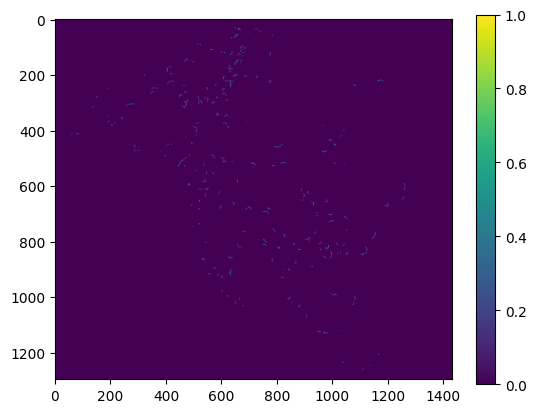

In [2]:
raster = rio.open('https://raw.githubusercontent.com/edieraristizabal/CartografiaGeotecnica/master/libro/data/miel/Inventario_MenM.tif')
inventario=raster.read(1)
print(inventario.shape)
plt.imshow(inventario)
plt.colorbar();

Para conocer los valores alamacenados en la capa se utiliza

In [5]:
np.unique(inventario)

array([0, 1], dtype=int16)

El mapa que se importó tiene como valores 1 para celdas sin movimientos en masa y 2 para celdas con movimientos en masa. Es mas adecuado tener el mapa con celdas con valor 0 para celdas sin MenM y con valor 1 para celdas con MenM, esto se puede reclasificar desde *GIS* antes de exportarlo o guardarlo. En este caso debemos crear una máscara que tenga el área de la cuenca, a partir de otro mapa, en este caso el mapa de pendientes. La máscara por defecto genera un mapa de valores cero para cualquier celda fuera de la cuenca y 255 para celdas que son parte de la cuenca. Modificamos esta máscara para que las celdas por fuera de la cuenca tengan un valor NaN.


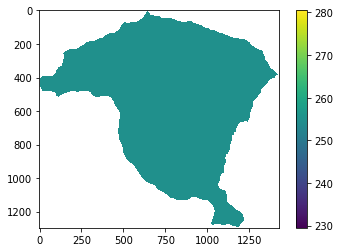

In [8]:
raster = rio.open('https://raw.githubusercontent.com/edieraristizabal/CartografiaGeotecnica/master/libro/data/miel/Pendiente.tif')
msk=raster.read_masks(1)
msk=np.where(msk==0,np.nan,msk)
plt.imshow(msk)
plt.colorbar();


In [10]:
np.unique(msk)

array([255.,  nan])

Y multiplicamos el inventario por la mascara y obtenemos el siguiente mapa, donde las celdas dentro de la cuenca que tienen MenM tienen un valor de 255 y sin MenM tienen un valor de 0. Por lo cual lo reclasificamos de tal forma que las celdas con MenM tengan valor de 1.

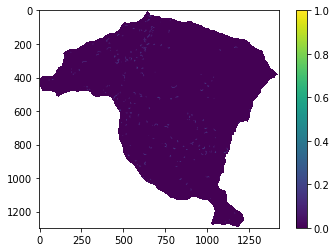

In [11]:
inventario=msk*inventario
inventario=np.where(inventario==255,1,inventario)
plt.imshow(inventario)
plt.colorbar();

In [12]:
np.unique(inventario)

array([ 0.,  1., nan])

## Actividades

1. **Análisis de densidad de inventario:** Usando el raster del inventario cargado, calcula el porcentaje de celdas con movimientos en masa dentro de la cuenca. ¿Qué porcentaje del área total está afectada? Compara este valor con datos reportados en la literatura para cuencas andinas colombianas.

2. **Comparación de cuencas:** Descarga el inventario de una segunda cuenca de tu región de interés. Compara visualmente la distribución espacial de los movimientos en masa. ¿En qué zonas se concentran? ¿Qué factores geomorfológicos podrían explicar esas diferencias?

3. **Calidad del inventario:** Investiga las diferencias entre un inventario *histórico* (basado en reportes) y uno *geomorfológico* (basado en interpretación de imágenes). ¿Cuál tiene mayor sesgo de detección? ¿Cómo afecta esto la estimación de susceptibilidad?

4. **Escala temporal:** Analiza el inventario multi-temporal reportado por {cite:t}`aristizabal2016` para el Valle de Aburrá. ¿Qué ventajas ofrece respecto a un inventario puntual para la estimación de amenaza?

## Referencias
```{bibliography}
:style: plain
:filter: docname in docnames
```